# Notebook 06: Learning the quit zone

**Project:** Hacker Statistics, chances of winning a bet  
Notebook 05 ended with an honest failure. The exact best rule for the stopping game pays 0.426, but the Q-learning program only reached 0.412, which is *worse* than the simple rule "roll until you reach 60" (0.414). It found the big idea (collect the prize at the target) and missed the small one (quit when the game is lost).

This notebook asks **why**, fixes it, and then tries a different kind of learner:

1. Find out which ingredients the learner was missing (two suspects, tested one at a time).
2. Tune how quickly the learner forgets old guesses.
3. Replace the table of scores with a small **neural network** and see which learner needs less experience.

Because the exact answer is known, every learner is scored against it.

**How each section is laid out:** what we are looking for, the code, its result, how to read it, what it means, and what's next and why.

## 1. Setup

### What we are looking for
Imports and the functions for this notebook, which live in `src/stopping.py` (tested in `tests/test_stopping.py`). The new ones are `q_learn_batch` (a much faster Q-learner that plays thousands of games at once), `fit_network` (the neural-network learner) and `score_rule` (compares any rule with the exact best).

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.stopping import (optimal_stopping, evaluate_policy, occupancy, greedy_roll_mask,
                          q_learn_batch, fit_network, score_rule)

RED, BLUE, GREY, GOLD = "#9A3B2E", "#2F6690", "#a39b93", "#A87613"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

ROLLS, TARGET, CLUMSY, FEE = 100, 60, 0.001, 0.005
SIZE = 6 * ROLLS + 8
print("Setup complete.")

Setup complete.


### How to read it
Nothing to interpret yet; the line confirms the imports worked.

### What it means
The game is the same as in notebook 05: 100 rolls, target step 60, 0.1% clumsiness, a fee of 0.005 per roll, and a choice to roll or stop after every roll.

### What's next and why
First we restate exactly what the learner failed to find, so that "fixed" has a clear meaning.

## 2. Where notebook 05 left off

### What we are looking for
The target to hit. We want to know: the best possible payoff, what the simple rule scores, how many positions (roll number, step) belong to the **quit zone**, and how big the payoff differences are there. If the differences are tiny, that would explain why the learner struggled.

In [2]:
W, cont, stop = optimal_stopping(ROLLS, TARGET, CLUMSY, FEE)
best_roll = cont[:ROLLS] >= stop[None, :]                      # True where rolling is at least as good as stopping
bank_at_target = np.tile(np.arange(SIZE) < TARGET, (ROLLS, 1))  # roll until you reach 60, then stop

below = np.arange(SIZE) < TARGET
quit_cells = (~best_roll) & below[None, :]                      # positions where the best rule quits
gap = (cont[:ROLLS] - stop[None, :])[quit_cells]                # how much worse rolling is than quitting there

print(f"Best possible payoff:                    {W[0, 0]:.4f}")
print(f"'Roll until you reach 60' rule:          {evaluate_policy(bank_at_target, ROLLS, TARGET, CLUMSY, FEE):.4f}")
print(f"Notebook 05's learner (reported there):  0.412")
print()
print(f"Positions in the quit zone:              {quit_cells.sum():,}")
print(f"Games that end by quitting:              {occupancy(best_roll, ROLLS, CLUMSY)[quit_cells].sum():.1%}")
print(f"Typical cost of rolling there (median):  {np.median(-gap):.4f} of a prize (one fee is {FEE})")

Best possible payoff:                    0.4259
'Roll until you reach 60' rule:          0.4145
Notebook 05's learner (reported there):  0.412

Positions in the quit zone:              1,459
Games that end by quitting:              14.7%
Typical cost of rolling there (median):  0.0050 of a prize (one fee is 0.005)


### How to read it
The first three lines are the scores to compare. The last three describe the quit zone: how many positions it has, how often a game ends in it and how much better quitting is than rolling in a typical quit position.

### What it means
The prize for finding the quit zone is the difference between 0.4259 and 0.4145, about 0.011 of a prize per game. That is small, and each quit position is worth only about one fee (0.005) over carrying on. A learner judging a position by a handful of played games cannot tell a 0.005 difference from luck. The zone is not rare, though: the best rule ends about one game in seven there. So the learner has plenty of chances to see it. Something else must be going wrong, and the next section tests two suspects.

### What's next and why
Two things in notebook 05's learner are suspicious. We test each alone and together, which is the only way to know which one matters.

## 3. Two suspects, tested one at a time

### What we are looking for
Which change lets the learner find the quit zone. The two suspects:

- **Suspect 1: where games start.** Every game in notebook 05 started at step 0, so positions deep in the quit zone (low step, late in the game) were visited only by games that had already gone badly, and only after the learner chose to keep rolling. **Fix: exploring starts.** Each practice game starts from a random position (random roll number, random step), so every position gets practice.
- **Suspect 2: stale optimism.** Every score starts at 1, the best possible payoff. A plain average (new score = average of everything seen so far) never fully lets go of those early, over-hopeful numbers, because the first experiences count as much as the last. **Fix: forgetting.** Each update moves the score at least 5% of the way to the newest average, so old guesses fade.

We test all four combinations. Each learner plays 5 million games (about 15 seconds each) and is scored exactly against the best rule: its payoff, how many of the 1,459 quit positions it found, how many positions it quit that it should have kept rolling in (**false quits**) and how many decisions it saw.

In [3]:
rows = []
for starts in (False, True):
    for forget in (0.0, 0.05):
        Q, N, _ = q_learn_batch(5_000_000, exploring_starts=starts, forget=forget, seed=0)
        s = score_rule(greedy_roll_mask(Q, ROLLS), ROLLS, TARGET, CLUMSY, FEE)
        rows.append((starts, forget, s["payoff"], s["quit_found"], s["false_quits"], N.sum() / 1e6))

print(f"{'Exploring starts':<18}{'Forgetting':<12}{'Payoff':>8}{'Quit found':>12}{'False quits':>13}{'Decisions (M)':>15}")
for starts, forget, pay, found, false_q, dec in rows:
    print(f"{('yes' if starts else 'no'):<18}{(forget if forget else 'none'):<12}{pay:>8.4f}{found:>9,} /1,459{false_q:>7,}{dec:>15.0f}")
print(f"\nBest possible payoff: {W[0, 0]:.4f}")

Exploring starts  Forgetting    Payoff  Quit found  False quits  Decisions (M)
no                none          0.4152       57 /1,459     30             98
no                0.05          0.4139       74 /1,459     40             98
yes               none          0.4161      154 /1,459      0             41
yes               0.05          0.4251    1,458 /1,459     74             33

Best possible payoff: 0.4259


### How to read it
Each row is one learner. "Payoff" is the exact expected payoff of the rule it learned. "Quit found" counts how many of the 1,459 true quit positions it quits in. "False quits" counts positions where it quits but should roll. "Decisions" is how many roll-or-stop decisions it saw, in millions.

### What it means
Neither fix works alone. Without exploring starts the learner finds only 57 or 74 of the quit positions whether or not it forgets. With exploring starts but no forgetting it finds 154 and makes no false quits, so it is cautious but still misses almost all of the zone. Only the combination works: **1,458 of 1,459 quit positions found and a payoff of 0.4251, within 0.0008 of the best possible 0.4259**, and clearly above the simple rule's 0.4145.

The two fixes solve two different problems. Exploring starts make sure the learner *visits* the quit positions. Forgetting makes sure it *believes what it sees there* instead of an early optimistic guess. A learner needs both the data and the willingness to update. Exploring starts also make learning cheaper: the winning learner saw 33 million decisions against 98 million for the two learners that always start at step 0, because games that start late in the game are short.

The price of forgetting is noise: 74 false quits. The next section looks at that trade-off.

### What's next and why
"5% forgetting" was our first guess, not a tuned value. Too little forgetting leaves old optimism in place, too much makes the scores jumpy. We sweep it.

## 4. How much forgetting?

### What we are looking for
The best forgetting setting, and what goes wrong on either side. We keep exploring starts, play 2 million games per setting and track the payoff and the false quits.

Forgetting    Payoff  Quit found  False quits
none          0.4159      123 /1,459      0
0.01          0.4197      551 /1,459      3
0.02          0.4223      919 /1,459     20
0.05          0.4249    1,433 /1,459     55
0.1           0.4247    1,457 /1,459    125
0.2           0.4188    1,459 /1,459    260
0.4           0.3923    1,459 /1,459    593


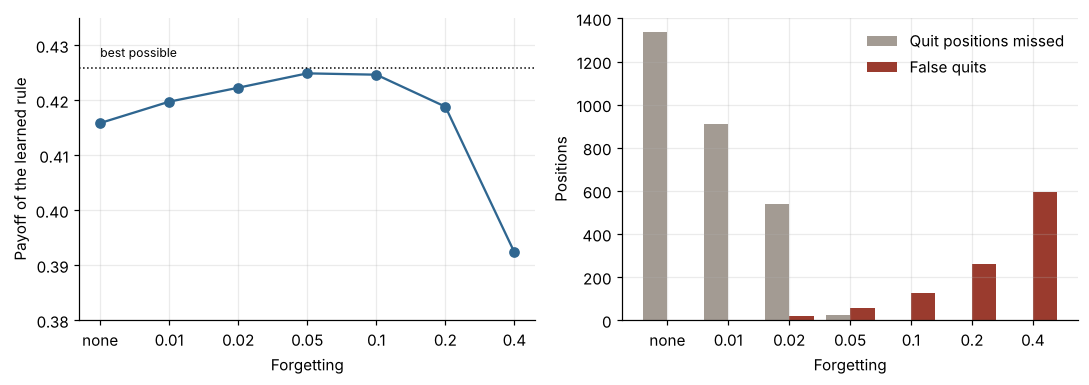

In [4]:
settings = [0.0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4]
sweep = []
for f in settings:
    Q, N, _ = q_learn_batch(2_000_000, forget=f, seed=0)
    sweep.append(score_rule(greedy_roll_mask(Q, ROLLS), ROLLS, TARGET, CLUMSY, FEE))

print(f"{'Forgetting':<12}{'Payoff':>8}{'Quit found':>12}{'False quits':>13}")
for f, s in zip(settings, sweep):
    print(f"{(f if f else 'none'):<12}{s['payoff']:>8.4f}{s['quit_found']:>9,} /1,459{s['false_quits']:>7,}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
x = np.arange(len(settings))
axes[0].plot(x, [s["payoff"] for s in sweep], "o-", color=BLUE)
axes[0].axhline(W[0, 0], color="black", ls=":", lw=1); axes[0].text(0, W[0, 0] + 0.002, "best possible", fontsize=8)
axes[0].set_ylim(0.38, 0.435); axes[0].set_ylabel("Payoff of the learned rule")
axes[1].bar(x - 0.2, [s["quit_cells"] - s["quit_found"] for s in sweep], 0.4, color=GREY, label="Quit positions missed")
axes[1].bar(x + 0.2, [s["false_quits"] for s in sweep], 0.4, color=RED, label="False quits")
axes[1].set_ylabel("Positions"); axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels([str(f) if f else "none" for f in settings]); ax.set_xlabel("Forgetting")
plt.tight_layout(); plt.show()

### How to read it
Left chart: the payoff of the learned rule at each setting; the dotted line is the best possible. Right chart: the two kinds of mistake. Grey bars are quit positions the learner missed, red bars are false quits.

### What it means
With no forgetting the learner misses nearly everything (123 of 1,459 found). Each step up in forgetting finds more of the quit zone, and the payoff peaks at 0.05 to 0.1 (0.4249 and 0.4247). Beyond that the red bars take over: at 0.2 the learner finds every quit position but makes 260 false quits, and at 0.4 it makes 593 and the payoff collapses to 0.392, below the simple rule. Heavy forgetting treats the last few games as the whole truth, so luck decides the rule.

This is a general pattern in learning from experience, not a quirk of this game: you need to let go of old information to correct it, but not so quickly that you chase noise. The best setting is in the middle, and we use 0.05.

### What's next and why
With the setting chosen, we watch the learner improve as it plays, to see how much practice it needs.

## 5. The learning curve

### What we are looking for
How the learned rule's payoff grows with practice, compared with the best possible rule and with "roll until 60". We freeze the learner every 500,000 games and score its rule exactly.

after   500,000 games: payoff 0.4196, quit positions found   609 / 1,459, false quits  23
after 1,000,000 games: payoff 0.4227, quit positions found 1,042 / 1,459, false quits  35
after 1,500,000 games: payoff 0.4240, quit positions found 1,282 / 1,459, false quits  49
after 2,000,000 games: payoff 0.4249, quit positions found 1,433 / 1,459, false quits  55
after 2,500,000 games: payoff 0.4251, quit positions found 1,458 / 1,459, false quits  75
after 3,000,000 games: payoff 0.4250, quit positions found 1,459 / 1,459, false quits  73
after 3,500,000 games: payoff 0.4253, quit positions found 1,458 / 1,459, false quits  72
after 4,000,000 games: payoff 0.4253, quit positions found 1,457 / 1,459, false quits  67
after 4,500,000 games: payoff 0.4253, quit positions found 1,459 / 1,459, false quits  72
after 5,000,000 games: payoff 0.4251, quit positions found 1,458 / 1,459, false quits  74


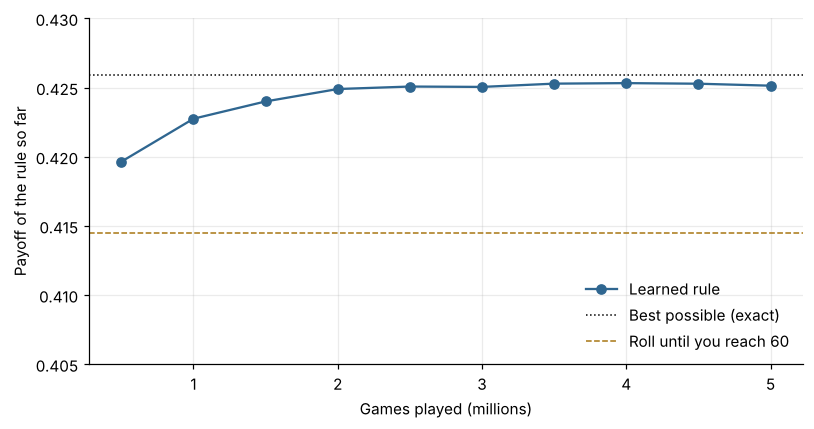

In [5]:
GAMES, EVERY = 5_000_000, 500_000
Q_table, N_table, snaps = q_learn_batch(GAMES, forget=0.05, seed=0, checkpoint_every=EVERY)
scores = [score_rule(m, ROLLS, TARGET, CLUMSY, FEE) for _, m in snaps]

for (g, _), s in zip(snaps, scores):
    print(f"after {g:>9,} games: payoff {s['payoff']:.4f}, quit positions found {s['quit_found']:>5,} / {s['quit_cells']:,}, false quits {s['false_quits']:>3}")

simple = evaluate_policy(bank_at_target, ROLLS, TARGET, CLUMSY, FEE)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot([g / 1e6 for g, _ in snaps], [s["payoff"] for s in scores], "o-", color=BLUE, label="Learned rule")
ax.axhline(W[0, 0], color="black", ls=":", lw=1, label="Best possible (exact)")
ax.axhline(simple, color=GOLD, ls="--", lw=1, label="Roll until you reach 60")
ax.set_xlabel("Games played (millions)"); ax.set_ylabel("Payoff of the rule so far")
ax.set_ylim(0.405, 0.43); ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

### How to read it
Each line of text is a frozen snapshot of the learner. The chart plots the same payoffs; the dotted line is the best possible and the dashed line is the simple rule.

### What it means
The learner is already past the simple rule after half a million games (0.4196 against 0.4145) and keeps improving: 0.4227 after one million, 0.4249 after two million. After about 2.5 million games it levels off at 0.425, within 0.001 of the best possible, and the extra games add nothing. The remaining gap is the 70 or so false quits from the previous section: the learner is a little jumpy in rarely visited corners, which costs almost nothing because it rarely goes there.

Notebook 05's learner needed 400,000 games to reach 0.412 and never got past the simple rule. This one passes it in under 500,000 and ends 0.013 higher. Some of that is the faster program (a few seconds per million games), but the exploring starts and forgetting are what make the difference.

### What's next and why
The table learner keeps a separate score for each of about 20,000 positions, so it learns each one on its own. Neighbouring positions are obviously related (step 30 and step 31 at the same roll should have similar values), but the table cannot use that. A neural network can.

## 6. A neural network instead of a table

### What we are looking for
Whether a small neural network, which sees the roll number and the step as two numbers and therefore *can* spot that neighbours are alike, learns the quit zone from less experience than the table.

The method is called **fitted Q iteration**. Each round:

1. Pick 40,000 random positions (roll number, step).
2. Roll the dice once from each, which gives a landing position.
3. Teach the network: *the value of rolling here = minus the fee, plus the best value of where I landed*, using the network's own current guesses for the landing positions.
4. Repeat. Knowledge about the end of the game spreads back by about one roll per round, so we run 100 rounds, one for each roll in the game.

Like the table learner it is never told the dice probabilities, only the results of rolls. The network has two hidden layers of 64 units. Quitting always pays 0, so the learned rule is: roll wherever the network says rolling is worth at least 0. To damp the round-to-round wobble, the final rule uses the average of the network's predictions over the last 20 rounds. We freeze and score the rule every 5 rounds.

after  20 rounds (  800,000 sampled rolls): payoff 0.0000, quit positions found 1,298, false quits 1610
after  30 rounds (1,200,000 sampled rolls): payoff 0.0000, quit positions found 1,297, false quits 1141
after  40 rounds (1,600,000 sampled rolls): payoff 0.0000, quit positions found 1,137, false quits 601
after  50 rounds (2,000,000 sampled rolls): payoff 0.0000, quit positions found 1,140, false quits 412
after  60 rounds (2,400,000 sampled rolls): payoff 0.0000, quit positions found 1,258, false quits 250
after  70 rounds (2,800,000 sampled rolls): payoff 0.4244, quit positions found 1,383, false quits  60
after  80 rounds (3,200,000 sampled rolls): payoff 0.4251, quit positions found 1,297, false quits   0
after  90 rounds (3,600,000 sampled rolls): payoff 0.4250, quit positions found 1,310, false quits   4
after 100 rounds (4,000,000 sampled rolls): payoff 0.4254, quit positions found 1,445, false quits  70

Final (averaged) rule:  payoff 0.4254, quit positions found 1,371 / 1,

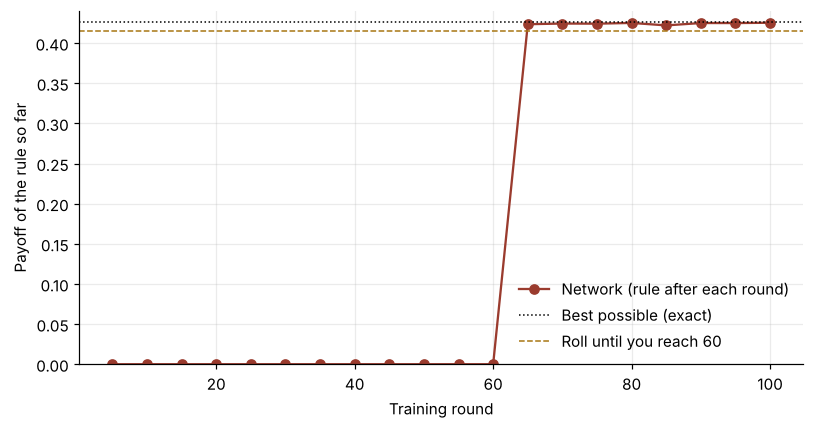

In [6]:
net, mask_net, net_snaps = fit_network(rounds=100, n=40_000, seed=0, checkpoint_every=5)
net_scores = [score_rule(m, ROLLS, TARGET, CLUMSY, FEE) for _, m in net_snaps]

for (r, _), s in list(zip(net_snaps, net_scores))[3::2]:
    print(f"after {r:>3} rounds ({r * 40_000:>9,} sampled rolls): payoff {s['payoff']:.4f}, quit positions found {s['quit_found']:>5,}, false quits {s['false_quits']:>3}")
final_net = score_rule(mask_net, ROLLS, TARGET, CLUMSY, FEE)
print(f"\nFinal (averaged) rule:  payoff {final_net['payoff']:.4f}, quit positions found {final_net['quit_found']:,} / {final_net['quit_cells']:,}, false quits {final_net['false_quits']}")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot([r for r, _ in net_snaps], [max(s["payoff"], 0.0) for s in net_scores], "o-", color=RED, label="Network (rule after each round)")
ax.axhline(W[0, 0], color="black", ls=":", lw=1, label="Best possible (exact)")
ax.axhline(simple, color=GOLD, ls="--", lw=1, label="Roll until you reach 60")
ax.set_xlabel("Training round"); ax.set_ylabel("Payoff of the rule so far"); ax.set_ylim(0, 0.44)
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

### How to read it
Each line is a snapshot of the network's rule after a number of rounds, with the total number of dice rolls it has been shown so far. The chart plots every fifth round. Payoffs below zero are shown as zero.

### What it means
For the first 60 rounds the network's rule scores exactly 0. It says "quit" almost everywhere, which is the same as never playing. The news about the prize at the end of the game has to spread backwards, one roll per round, and until enough of it has arrived the network believes rolling is not worth the fee. Then between round 60 and round 65 the payoff jumps to about 0.42 and stays there: 0.4244 at round 70, 0.4251 at round 80 and 0.4254 at round 100, after about 4 million sampled rolls.

The final averaged rule pays **0.4254, within 0.0005 of the best possible 0.4259** and as good as the table learner's 0.4251. It finds 1,371 of the 1,459 quit positions and makes only 2 false quits, so it is more cautious than the table at the edge of the quit zone. That costs almost nothing, because the positions it misses are the ones where quitting is only just better than rolling.

### What's next and why
The network looks good after one run, but one run can be luck, and the question was about *experience*, so we compare the two learners fairly: the same payoff measured against the amount of data each one used.

## 7. Which learner needs less experience?

### What we are looking for
The payoff each learner reaches for a given amount of experience, counted as the number of dice rolls it has seen. For the table that is the number of decisions it saw (a few of them are stops, which need no roll, so this slightly flatters the table). For the network it is rounds times positions per round (100 rounds each). We repeat each budget with three different random seeds, so luck shows up as spread instead of hiding in one number.

Learner       Rolls seen   Lowest  Average  Highest
Table            432,283   0.4125   0.4127   0.4132
Table          1,568,229   0.4156   0.4167   0.4177
Table          4,590,419   0.4208   0.4211   0.4214
Table         14,498,912   0.4239   0.4241   0.4242
Table         35,300,290   0.4252   0.4254   0.4255
Network          250,000   0.4163   0.4187   0.4222
Network          500,000   0.4166   0.4192   0.4236
Network        1,000,000   0.4218   0.4224   0.4233
Network        2,000,000   0.4195   0.4233   0.4254


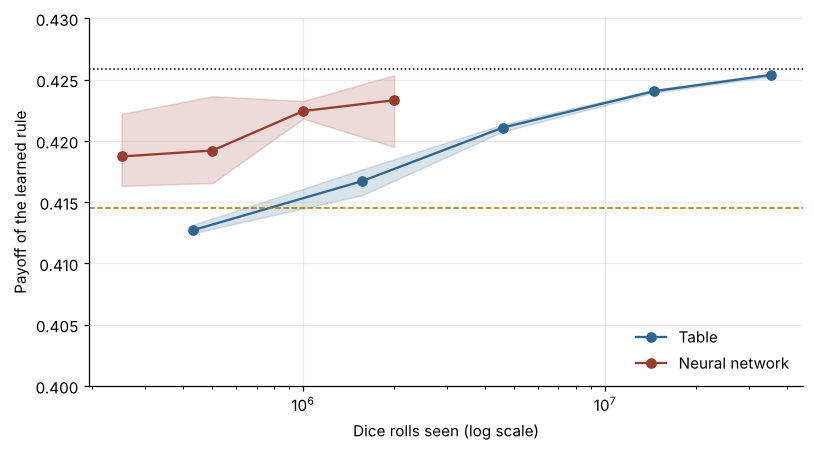

In [7]:
table_pts, net_pts = [], []
for g in [60_000, 200_000, 600_000, 2_000_000, 5_000_000]:
    res = []
    for seed in range(3):
        Q, N, _ = q_learn_batch(g, batch=max(2_000, g // 50), forget=0.05, seed=seed)
        res.append((N.sum(), score_rule(greedy_roll_mask(Q, ROLLS), ROLLS, TARGET, CLUMSY, FEE)["payoff"]))
    table_pts.append((np.mean([r[0] for r in res]), [r[1] for r in res]))
for n in [2_500, 5_000, 10_000, 20_000]:
    res = [score_rule(fit_network(rounds=100, n=n, seed=seed)[1], ROLLS, TARGET, CLUMSY, FEE)["payoff"] for seed in range(3)]
    net_pts.append((100 * n, res))

print(f"{'Learner':<10}{'Rolls seen':>14}{'Lowest':>9}{'Average':>9}{'Highest':>9}")
for name, pts in (("Table", table_pts), ("Network", net_pts)):
    for budget, pays in pts:
        print(f"{name:<10}{budget:>14,.0f}{min(pays):>9.4f}{np.mean(pays):>9.4f}{max(pays):>9.4f}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for pts, color, label in ((table_pts, BLUE, "Table"), (net_pts, RED, "Neural network")):
    xs = [b for b, _ in pts]
    ax.plot(xs, [np.mean(p) for _, p in pts], "o-", color=color, label=label)
    ax.fill_between(xs, [min(p) for _, p in pts], [max(p) for _, p in pts], color=color, alpha=0.18)
ax.axhline(W[0, 0], color="black", ls=":", lw=1); ax.axhline(simple, color=GOLD, ls="--", lw=1)
ax.set_xscale("log"); ax.set_ylim(0.40, 0.43)
ax.set_xlabel("Dice rolls seen (log scale)"); ax.set_ylabel("Payoff of the learned rule"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

### How to read it
Each row is a budget of experience (rolls seen) with the lowest, average and highest payoff over three seeds. On the chart the line is the average and the shaded band is the lowest-to-highest range. The dotted line is the best possible and the dashed line the simple rule. The horizontal axis is logarithmic: each tick is ten times more experience.

### What it means
The network's line sits above the table's at every budget the two share. With 250,000 to 500,000 rolls the network averages about 0.419. The table needs about 4.6 million rolls to average 0.421 and about 14.5 million (0.4241) to match what the network gets from one to two million (0.4224 and 0.4233). **For the same payoff the network needs roughly 5 to 10 times less experience**, which is what you would expect from a learner that can use the fact that neighbouring positions are alike.

Two caveats. First, the network is less predictable: at two million rolls its three runs range from 0.4195 to 0.4254 (the shaded band), while the table's three runs are almost identical at every budget. Second, we only ran the network up to two million rolls here (section 6 used four million and reached 0.4254). The table is slow, but it improves steadily and reaches an average of 0.4254 at 35 million rolls. So the table is the more predictable learner and the network is the more thrifty one.

### What's next and why
Payoff is one number. To see *what* each learner understood, we compare the rules themselves with the exact one as maps.

## 8. The three rules side by side

### What we are looking for
The exact best rule next to the table learner's rule and the network's rule, drawn as the same map as in notebook 05: horizontal axis the roll number, vertical axis the step, with colours for collect (blue), keep rolling (grey) and quit (red). Then a number for how much each learner differs from the exact rule.

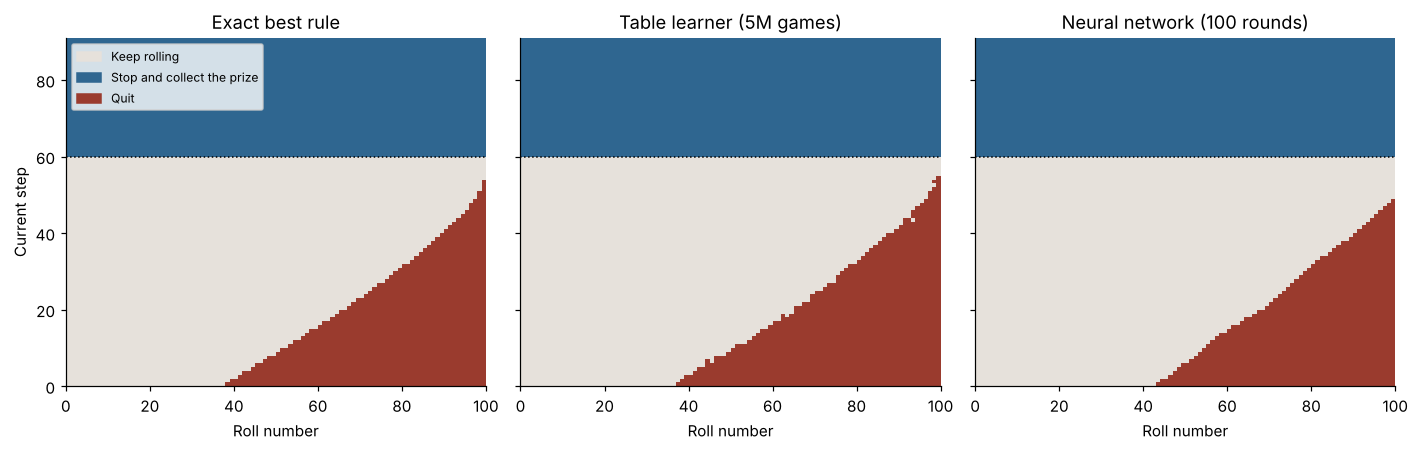

Learner            Positions that differ   Share of play spent there   Payoff
Table                               0.1%                       0.24%   0.4251
Neural network                      0.1%                       0.11%   0.4254


In [8]:
def policy_image(roll_mask, max_step=90):
    # 0 = roll, 1 = collect the prize, 2 = quit
    img = np.zeros((max_step + 1, ROLLS))
    for t in range(ROLLS):
        for s in range(max_step + 1):
            img[s, t] = 0 if roll_mask[t, s] else (1 if s >= TARGET else 2)
    return img

mask_table = greedy_roll_mask(Q_table, ROLLS)
cmap = ListedColormap(["#e6e1db", BLUE, RED])
legend = [Patch(color="#e6e1db", label="Keep rolling"), Patch(color=BLUE, label="Stop and collect the prize"), Patch(color=RED, label="Quit")]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, m, title in zip(axes, (best_roll, mask_table, mask_net), ("Exact best rule", "Table learner (5M games)", "Neural network (100 rounds)")):
    ax.imshow(policy_image(m), origin="lower", aspect="auto", cmap=cmap, vmin=0, vmax=2, extent=[0, ROLLS, 0, 91])
    ax.axhline(TARGET, color="black", ls=":", lw=1); ax.set_xlabel("Roll number"); ax.set_title(title); ax.grid(False)
axes[0].set_ylabel("Current step"); axes[0].legend(handles=legend, loc="upper left", frameon=True, fontsize=8)
plt.tight_layout(); plt.show()

occ = occupancy(best_roll, ROLLS, CLUMSY)
print(f"{'Learner':<16}{'Positions that differ':>24}{'Share of play spent there':>28}{'Payoff':>9}")
for name, m in (("Table", mask_table), ("Neural network", mask_net)):
    diff = (m != best_roll)
    print(f"{name:<16}{diff.mean():>24.1%}{occ[diff].sum() / occ.sum():>28.2%}{evaluate_policy(m, ROLLS, TARGET, CLUMSY, FEE):>9.4f}")

### How to read it
Three maps with the same axes and colours. The table underneath counts, for each learner, the share of all positions where its action differs from the exact rule, and the share of a best-rule climber's time spent in those positions.

### What it means
All three maps tell the same story. The quit wedge starts at the bottom around roll 38 to 43 and climbs to the right, the collect zone is the same everywhere above step 60, and the keep-rolling zone fills the rest.

The differences are at the edges. The table learner's border is ragged: a few cells inside the wedge's edge flip the wrong way, and near the end of the game the wedge reaches a step or two too high. The network's border is smooth, but its wedge starts a few rolls late (about roll 43 against 38) and stops a few steps short at the top right (about step 49 against 54). It is the more cautious of the two, which matches its 2 false quits and 1,371 found.

The table underneath puts a number on it: only 0.1% of all positions differ from the exact rule for either learner, and a climber following the best rule spends 0.24% of its time in the table learner's differing positions and 0.11% in the network's. Both rules are very close to the exact one.

### What's next and why
That completes the comparison. The summary collects the results.

## 9. Summary

| Question | Result | Method |
|---|---|---|
| Why did notebook 05's learner miss the quit zone? | Two causes at once: games always started at step 0, and early optimistic scores were never forgotten | Four-way test of exploring starts and forgetting |
| Does either fix work alone? | No: 57 to 154 of 1,459 quit positions found | Four-way test |
| Both together | 1,458 of 1,459 found, payoff 0.4251 against the best 0.4259 | Q-learning with exploring starts and forgetting 0.05 |
| How much forgetting? | 0.05 to 0.1 is best; 0.4 drops below the simple rule | Sweep over seven settings |
| Practice needed | passes the simple rule after 0.5 million games, levels off after about 2.5 million | Learning curve scored exactly |
| Neural network vs table | about 5 to 10 times less experience for the same payoff, but results vary more between runs | Fitted Q iteration, three seeds per budget |

**Takeaways**
1. When a learner misses something, find out why by changing one thing at a time. Here the failure had two causes, and each fix alone did nothing.
2. A learner needs both **data in the right places** (exploring starts) and **willingness to revise old beliefs** (forgetting). Too much forgetting is as bad as too little.
3. Small differences need a lot of evidence. The quit zone is worth 0.012 of a prize, and each position about one fee, so it took millions of games to see it.
4. A network that can see that neighbouring positions are alike learns from roughly 5 to 10 times less experience than a table, but its results vary more from run to run. Generalizing trades some reliability for thrift.
5. Because the exact answer exists, we could say precisely *how close* each learner got, instead of trusting that it "seems to work".

**Where the code lives:** `src/stopping.py` (functions `q_learn_batch`, `fit_network`, `score_rule`), covered by `tests/test_stopping.py`.